# Bifrost code ``eostable.dat`` EOS consistency check

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as pl
import scipy
import scipy.io
import scipy.interpolate
import sys
import os

In [3]:
top='c:/cygwin64/home/codes/dispatch2/'
sys.path.insert(0,top+'utilities/python')

In [4]:
import dispatch

## Read EOS data

In [73]:
import dispatch.EOS
eos=dispatch.EOS.open('bifrost',top=top,verbose=0)
eos.variables

{0: 'ln(P)', 1: 'T', 2: 'ln(Ne)', 3: 'ln(rkap)'}

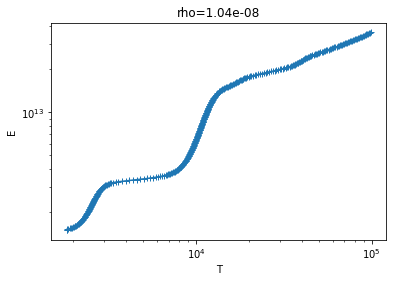

In [6]:
j=300
d=np.exp(eos.scale0.values[j])
lnE,lnP=eos.values(j,'ln(P)')
lnE,T=eos.values(j,'T')
P=np.exp(lnP)
lnT=np.log(T)
E=np.exp(lnE)
w=np.where(abs(lnT/np.log(10)-4)<1)[0]
pl.loglog(T[w],E[w],'-+')
pl.title('rho={:.2e}'.format(d))
pl.xlabel('T'); pl.ylabel('E');

## Differences in cross-derivatives

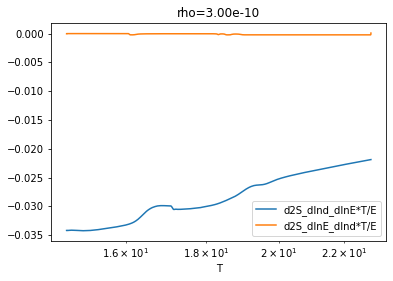

In [16]:
from dispatch.EOS import deriv,interp

def d2S_dlnE_dlnd(j0):
    def dS_dlnE(j):
        lnE,T=eos.values(j,'T')
        E=np.exp(lnE)
        return E/T,E,T
    j1=j0+1
    dS_dlnE_0,E0,T0=dS_dlnE(j0)        # dS_dlnE on E0 scale
    dS_dlnE_1,E1,T1=dS_dlnE(j1)        # dS_dlnE on E1 scale
    dS_dlnE_1=interp(E1,dS_dlnE_1,E0)  # dS_dlnE on E0 scale
    T1=interp(E1,T1,E0)                # T1 on E0 scale
    lnd_step=eos.scale0.step
    return (dS_dlnE_1-dS_dlnE_0)/lnd_step*(T0+T1)/(E0+E0),T1

def d2S_dlnd_dlnE(j0):
    """ \partial S^2 \over \partial\ln\rho \partial\ln E """
    def d2S(j):
        d=np.exp(eos.scale0.values[j])
        lnE,lnP=eos.values(j,'ln(P)')
        lnE,T=eos.values(j,'T')
        P=np.exp(lnP)
        lnT=np.log(T)
        E=np.exp(lnE)
        dS_dlnd=-P/(d*T)
        return deriv(lnE,dS_dlnd),E,T,lnE
    j1=j0+1
    d2S0,E0,T0,lnE0=d2S(j0)
    d2S1,E1,T1,lnE1=d2S(j1)
    d2S1=interp(E1,d2S1,E0)
    T1=interp(E1,T1,E0)
    return (d2S0+d2S1)/2*(T0+T1)/(E0+E0),T1
i=350
d2S_1,T1=d2S_dlnE_dlnd(i)
d2S_2,T2=d2S_dlnd_dlnE(i)
pl.semilogx(T1,d2S_1,label='d2S_dlnd_dlnE*T/E')
pl.semilogx(T1,d2S_2,label='d2S_dlnE_dlnd*T/E')
d=np.exp(eos.scale0.values[i])
pl.legend(); pl.title('rho={:.2e}'.format(d)); pl.xlabel('T');

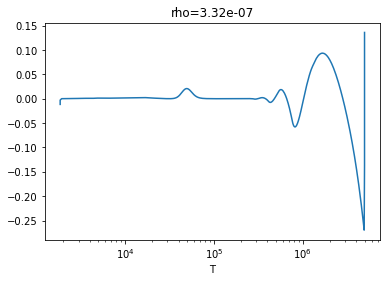

In [8]:
pl.semilogx(T1,d2S_1-d2S_2,label='difference');
pl.title('rho={:.2e}'.format(d)); pl.xlabel('T');

In the range below 500,000 K, the onconsistencies are relatively small, except for a feature associated with He-ionization:

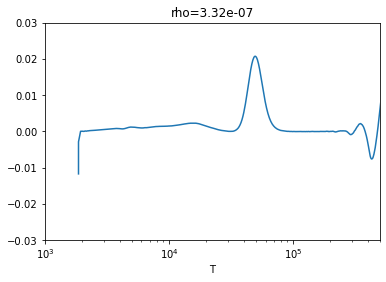

In [9]:
pl.ylim(-0.03,0.03); pl.xlim(1e3,5e5)
pl.semilogx(T1,d2S_1-d2S_2,label='difference');
pl.title('rho={:.2e}'.format(d)); pl.xlabel('T');

Multiple densities:

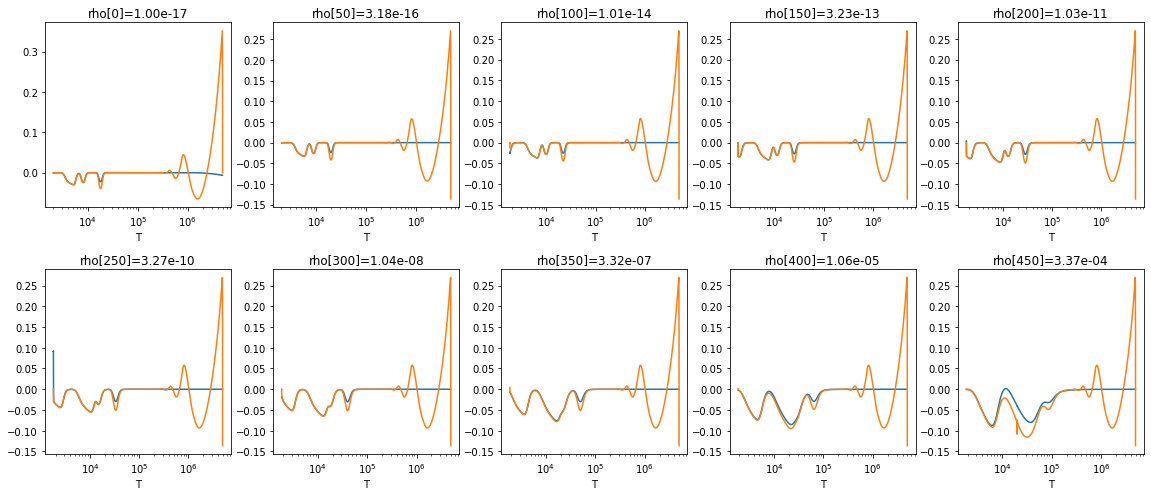

In [10]:
pl.figure(figsize=(16,7))
ip=1
Plot=pl.semilogx
for i in range(0,eos.scale0.n,50):
    d2S_1,T1=d2S_dlnE_dlnd(i)
    d2S_2,T2=d2S_dlnd_dlnE(i)
    pl.subplot(2,5,ip); ip+=1
    Plot(T1,d2S_1)
    Plot(T1,d2S_2)
    d=np.exp(eos.scale0.values[i])
    pl.title('rho[{}]={:.2e}'.format(i,d)); pl.xlabel('T');
pl.tight_layout()

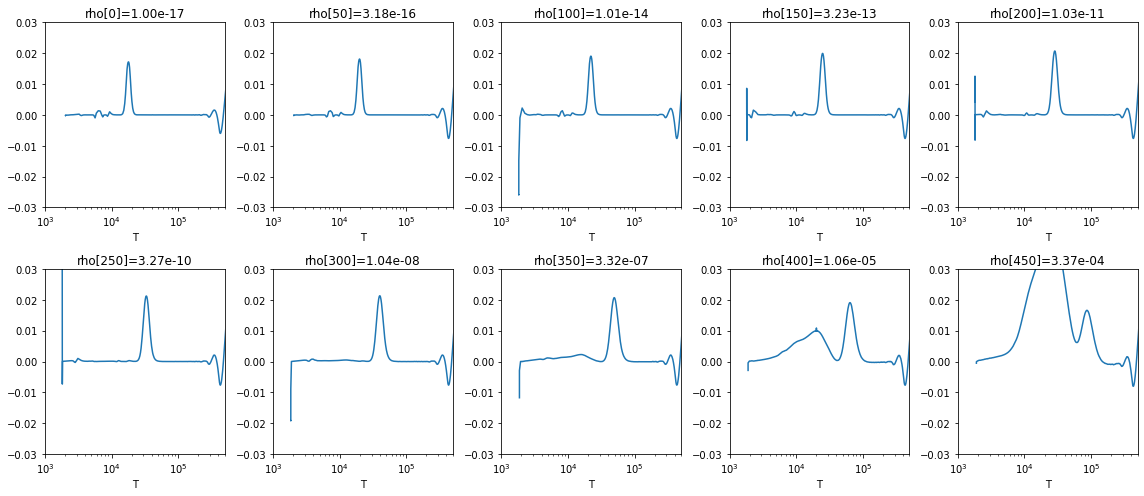

In [11]:
pl.figure(figsize=(16,7))
ip=1
Plot=pl.semilogx
for i in range(0,eos.scale0.n,50):
    d2S_1,T1=d2S_dlnE_dlnd(i)
    d2S_2,T2=d2S_dlnd_dlnE(i)
    pl.subplot(2,5,ip); ip+=1
    Plot(T1,d2S_1-d2S_2)
    d=np.exp(eos.scale0.values[i])
    pl.title('rho[{}]={:.2e}'.format(i,d)); pl.xlabel('T');
    pl.ylim(-0.03,0.03); pl.xlim(1e3,5e5)
pl.tight_layout()

## Read and investigate the new Bifrost/TABGEN output

In [6]:
os.chdir('c:/cygwin64/home/codes/bifrost/TABGEN/M')

In [7]:
eos=dispatch.EOS.bifrost('eostable.dat')

In [8]:
s0=eos.scale0
s1=eos.scale1
eos.type,eos.nv,s0.n,s0.max,s0.name,s1.n,s1.step,s1.name

('bifrost',
 4,
 851,
 1.0986122886681073,
 'ln(rho)',
 601,
 0.009332512401685976,
 'ln(E)')

In [9]:
eos.variables

{0: 'ln(P)', 1: 'T', 2: 'ln(Ne)', 3: 'ln(rkap)'}

## Solar Model S

In [10]:
from dispatch.solar_models import JCD_S
model=JCD_S(top=top)

Get ``(log(rho),log(E))``

In [17]:
def model_S(eos):
    """ Return (log10(rho), log10(E)), where rho[i] is from JCD model S, and
        E is the EOS enegy E[i] that corresponds to T[i] from the model.
    """
    s0=eos.scale0
    vars=eos.variables.values()
    ln10=np.log(10.0)
    LogE=[]
    LogD=[]
    for i,rho in enumerate(model.rho):
        Ti=model.T[i]
        lnd=np.log(model.rho[i])
        if lnd < s0.max:                              # only consider densities in the table
            ir,p=s0.index(lnd)                        # find the table
            if ir<s0.n:                               # only consider points inside
                lnE,T=eos.values(ir,'T')              # get T(lnE)
                lnT=np.log(T)                         # log T
                lnTi=np.log(Ti)                       # log T_S
                j=np.where(lnT>lnTi)[0]               # the part where lnT is larger
                if len(j)>1:
                    j=max(j[0]-2,0)
                    lnT=lnT[j:-1]
                    lnE=lnE[j:-1]                     # a part that covers lnTi
                    #print(i,lnTi,lnT[1:]-lnT[0:-1])
                    try:
                        log_E=interp(lnT,lnE,lnTi)/ln10
                        LogE.append(log_E)
                        LogD.append(np.log10(rho))
                    except:
                        #print('skipping',i,model.rho[i])
                        pass
    return np.array(LogD),np.array(LogE)

Compute and plot log10(rho),log10(T) for Model S

0.50087108 3.1171796


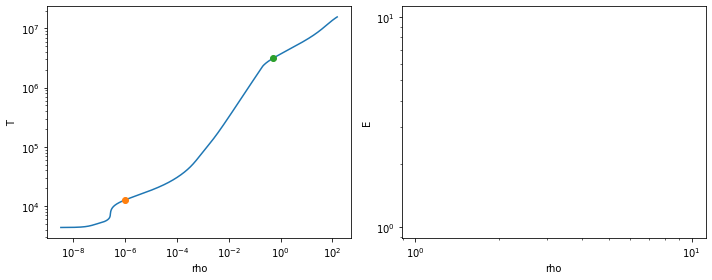

In [18]:
model=dispatch.solar_models.JCD_S(top=top)

pl.figure(figsize=(10,4))
pl.subplot(1,2,1)
w=np.where(model.rho<1e3)[0]
pl.loglog(model.rho[w],model.T[w]);
w=np.where(model.rho>1e-6)[0][0]
rho,T=model.rho[w],model.T[w]
pl.loglog(rho,T,'o')
w=np.where(model.rho>0.5)[0][0]
rho,T=model.rho[w],model.T[w]
pl.loglog(rho,T,'o')
print(rho,T/1e6)
pl.xlabel('rho')
pl.ylabel('T')

# 
logD,logE=model_S(eos)
pl.subplot(1,2,2)
w=np.where(10**logD<2)[0]
pl.loglog(10.**logD[w],10.**logE[w])
pl.xlabel('rho')
pl.ylabel('E')
pl.tight_layout();

So, to cover the CZ, the EOS has to reach a temperature of at least 3 MK

### Display inconsistencies, with Model S overlay

In [19]:
os.chdir('c:/cygwin64/home/codes/bifrost/TABGEN/M')

Compute array with inconsistency measure:

In [67]:
def Plot(title=''):
    pl.figure(figsize=(12,4))
    for i in (0,1):
        pl.subplot(1,2,1+i)
        lnE=eos.scale1.values
        lnd=eos.scale0.values
        ln10=np.log(10)
        e=(eos.scale0.min/ln10,eos.scale0.max/ln10,lnT0.min()/ln10,lnT0.max()/ln10)
        w=np.where(model.rho<10.)[0]
        if i:
            cl=np.log10(np.abs(cT)+1e-10)
            pl.imshow(cl.T,vmin=-5,vmax=-1,extent=e,aspect='auto',origin='lower')
            pl.title(eos.file+'  log10(abs(error)')
        else:
            vmax=2e-2
            pl.imshow(cT.T,vmin=-vmax,vmax=vmax,cmap='coolwarm',extent=e,aspect='auto',origin='lower')
            pl.title(title)
        pl.xlabel('log10(rho)'); pl.ylabel('log10(T)')
        pl.colorbar()
        pl.plot(np.log10(model.rho[w]),np.log10(model.T[w]),color='r')
        pl.xlim(-10,-1); pl.ylim(3.3,6);
    pl.tight_layout()

In [68]:
eos=dispatch.EOS.bifrost('eostable.dat')

c=np.zeros((eos.scale0.n,eos.scale1.n))
for i in range(1,eos.scale0.n-1):
    c[i,:]=dispatch.EOS.inconsistency(eos,i)

lnT0=np.linspace(np.log(2000),np.log(1e6),eos.scale1.n)
cT=np.copy(c)
for i in range(eos.scale0.n):
    lnE,T=eos.values(i,'T')
    lnT=np.log(T)
    dlnT=lnT[1:]-lnT[0:-1]
    w=np.where(dlnT!=0.0)[0]
    lnT=lnT[w]
    lnE=lnE[w]
    lnE0=interp(lnT,lnE,lnT0)
    c1=c[i]
    cT[i]=interp(eos.scale1.values,c1,lnE0)

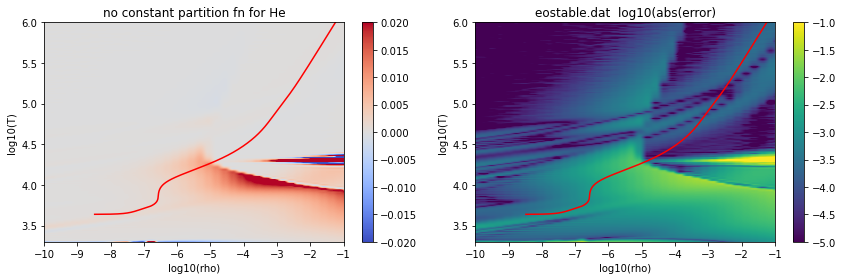

In [69]:
Plot('no constant partition fn for He')

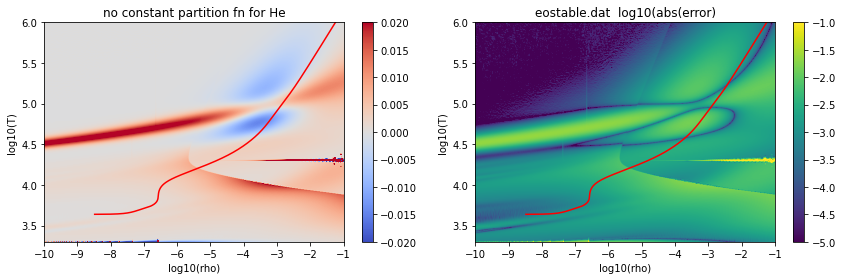

In [219]:
Plot('no constant partition fn for He')

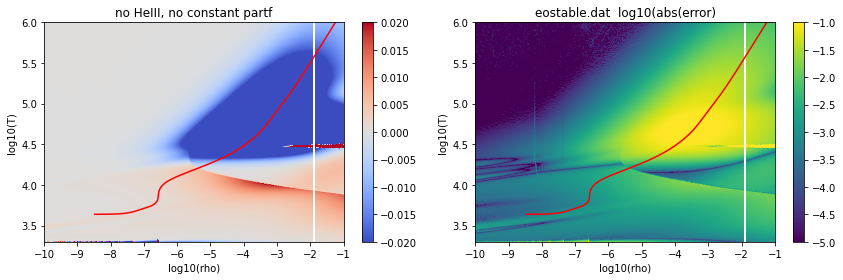

In [216]:
Plot('no HeIII, no constant partf')

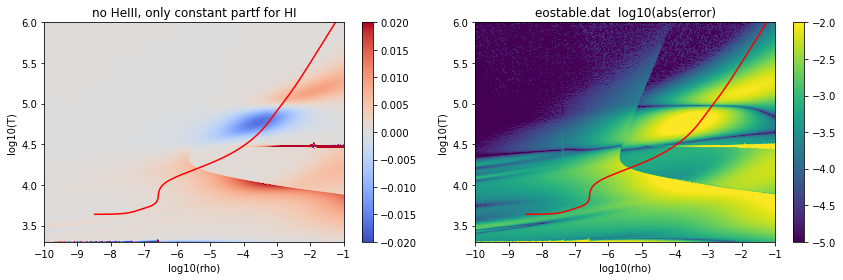

In [211]:
Plot('no HeIII, only constant partf for HI')

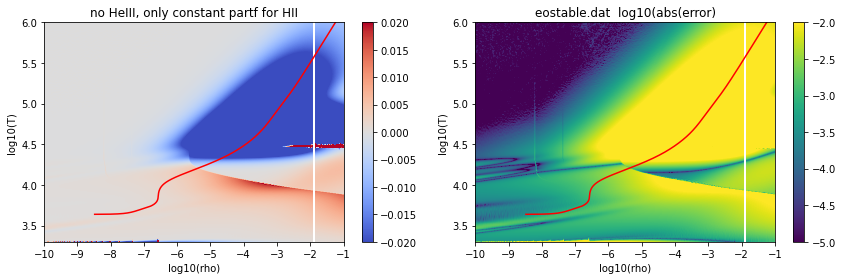

In [209]:
Plot('no HeIII, only constant partf for HII')

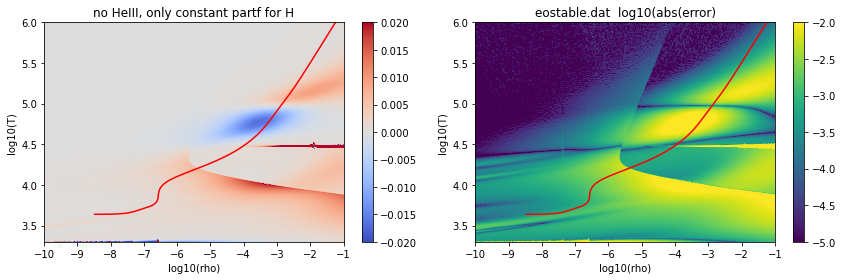

In [207]:
Plot('no HeIII, only constant partf for H')

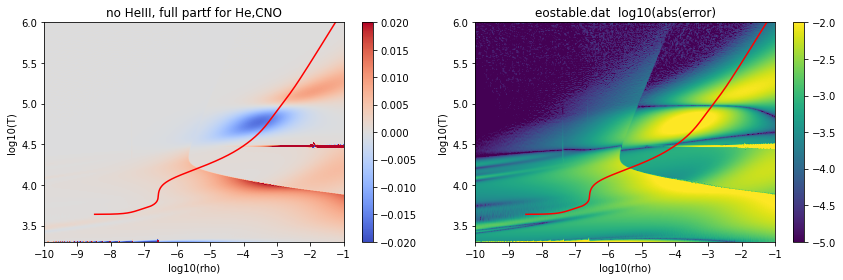

In [205]:
Plot('no HeIII, full partf for He,CNO')

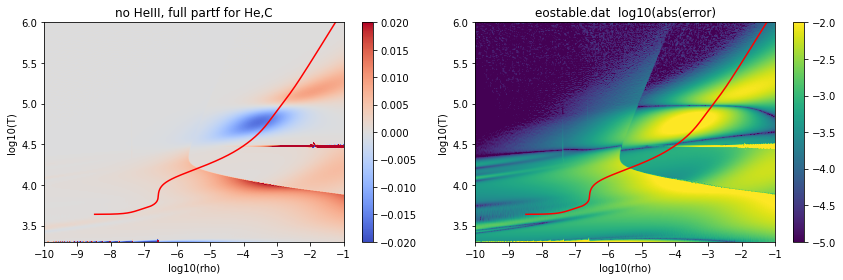

In [203]:
Plot('no HeIII, full partf for He,C')

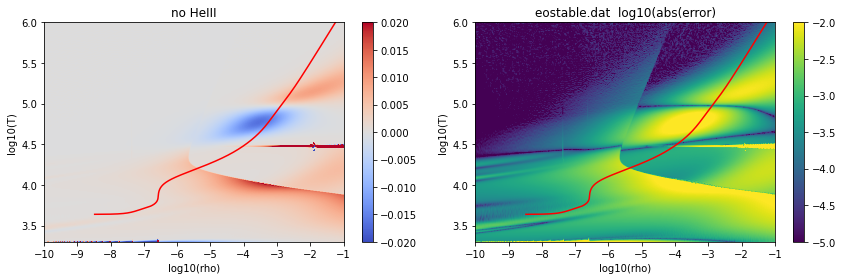

In [200]:
Plot('no HeIII')

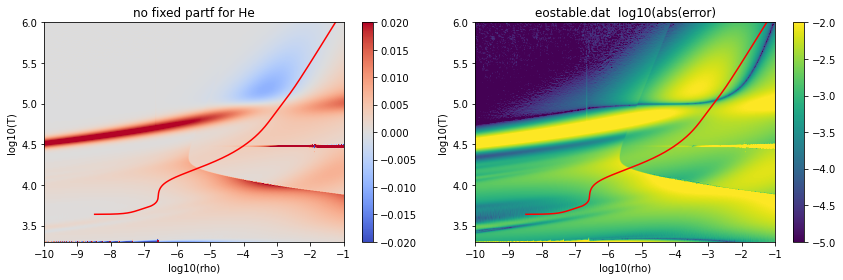

In [197]:
Plot('no fixed partf for He')

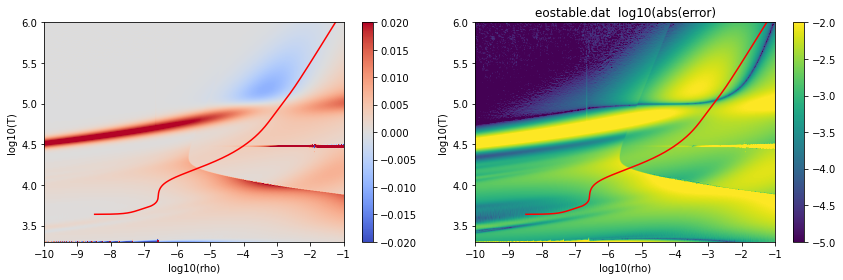

In [196]:
Plot()

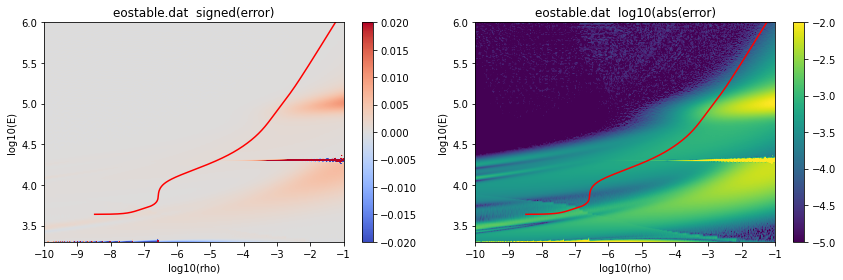

In [183]:
pl.figure(figsize=(12,4))
for i in (0,1):
    pl.subplot(1,2,1+i)
    lnE=eos.scale1.values
    lnd=eos.scale0.values
    ln10=np.log(10)
    e=(eos.scale0.min/ln10,eos.scale0.max/ln10,lnT0.min()/ln10,lnT0.max()/ln10)
    w=np.where(model.rho<10.)[0]
    if i:
        cl=np.log10(np.abs(cT)+1e-10)
        pl.imshow(cl.T,vmin=-5,vmax=-2,extent=e,aspect='auto',origin='lower')
        pl.title(eos.file+'  log10(abs(error)')
    else:
        vmax=2e-2
        pl.imshow(cT.T,vmin=-vmax,vmax=vmax,cmap='coolwarm',extent=e,aspect='auto',origin='lower')
        pl.title(eos.file+'  signed(error)')
    pl.xlabel('log10(rho)'); pl.ylabel('log10(T)')
    pl.colorbar()
    pl.plot(np.log10(model.rho[w]),np.log10(model.T[w]),color='r')
    pl.xlim(-10,-1); pl.ylim(3.3,6);
pl.tight_layout()

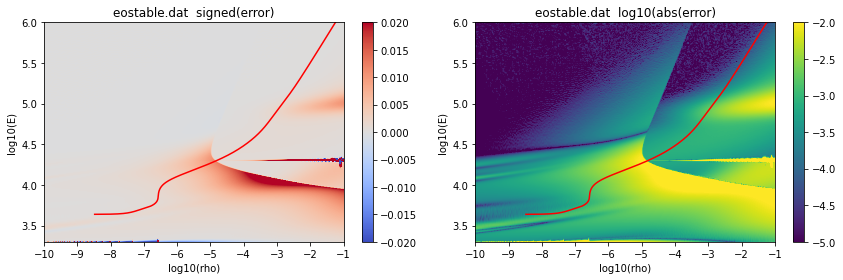

In [177]:
pl.figure(figsize=(12,4))
for i in (0,1):
    pl.subplot(1,2,1+i)
    lnE=eos.scale1.values
    lnd=eos.scale0.values
    ln10=np.log(10)
    e=(eos.scale0.min/ln10,eos.scale0.max/ln10,lnT0.min()/ln10,lnT0.max()/ln10)
    w=np.where(model.rho<10.)[0]
    if i:
        cl=np.log10(np.abs(cT)+1e-10)
        pl.imshow(cl.T,vmin=-5,vmax=-2,extent=e,aspect='auto',origin='lower')
        pl.title(eos.file+'  log10(abs(error)')
    else:
        vmax=2e-2
        pl.imshow(cT.T,vmin=-vmax,vmax=vmax,cmap='coolwarm',extent=e,aspect='auto',origin='lower')
        pl.title(eos.file+'  signed(error)')
    pl.xlabel('log10(rho)'); pl.ylabel('log10(E)')
    pl.colorbar()
    pl.plot(np.log10(model.rho[w]),np.log10(model.T[w]),color='r')
    pl.xlim(-10,-1); pl.ylim(3.3,6);
pl.tight_layout()

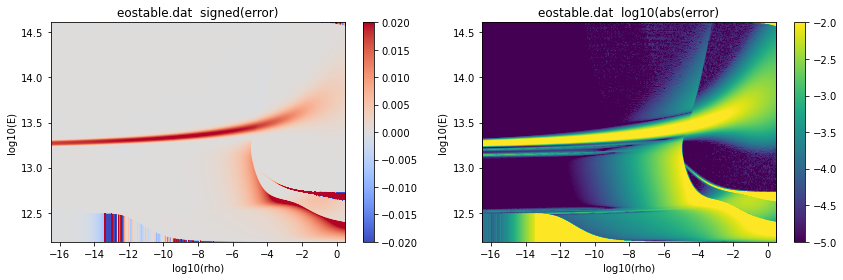

In [84]:
pl.figure(figsize=(12,4))
for i in (0,1):
    pl.subplot(1,2,1+i)
    lnE=eos.scale1.values
    lnd=eos.scale0.values
    ln10=np.log(10)
    e=(eos.scale0.min/ln10,eos.scale0.max/ln10,eos.scale1.min/ln10,eos.scale1.max/ln10)
    w=np.where(model.rho<10.)[0]
    if i:
        cl=np.log10(np.abs(c)+1e-10)
        pl.imshow(cl.T,vmin=-5,vmax=-2,extent=e,aspect='auto',origin='lower')
        pl.title(eos.file+'  log10(abs(error)')
    else:
        vmax=2e-2
        pl.imshow(c.T,vmin=-vmax,vmax=vmax,cmap='coolwarm',extent=e,aspect='auto',origin='lower')
        pl.title(eos.file+'  signed(error)')
    pl.xlabel('log10(rho)'); pl.ylabel('log10(E)')
    pl.colorbar()
    #pl.plot(np.log10(model.rho[w]),np.log10(model.T[w]),color='r')
    #pl.xlim(-10,0); pl.ylim(3,7);
pl.tight_layout()

In [27]:
eos.tables[1]['T'].values.max()

1881638.8